<a href="https://colab.research.google.com/github/Ruvee-2008/2604-ML-CW/blob/main/2609830.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Task 01**

In [16]:
import pandas as pd


In [17]:
df=pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [18]:
print("Number of coloumns and rows  : ",df.shape)
print("Data information             : ",df.info)
print("Fist 5 rows                  : ",df.head())
print("Missing values               : ",df.isnull().sum())

Number of coloumns and rows  :  (7043, 21)
Data information             :  <bound method DataFrame.info of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService 

The initial dataset inspection revealed that the dataset contains **7043 rows** and **21 columns**. The first five rows were displayed to provide an overview of the data, and the dataset was examined to identify missing values in each column.


In [19]:
print("Number of yes and no in churns : ")
print(df['Churn'].value_counts())
print("Number of yes and no of churns in percentages  :  ")
print(df['Churn'].value_counts(normalize=True)*100)

Number of yes and no in churns : 
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Number of yes and no of churns in percentages  :  
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


The analysis of customer churn revealed that approximately **73.46%** of customers did not churn, while **26.53%** of customers discontinued their services. This indicates that the majority of customers remained with the company, whereas approximately onequarter decided to leave.


## Data Visualization

---



### Churn vs Not Churn





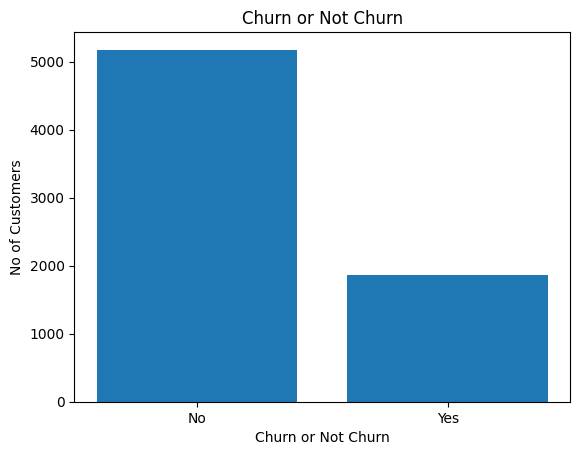

In [20]:
import matplotlib.pyplot as plt
curn_count=df['Churn'].value_counts()
plt.bar(curn_count.index,curn_count.values)
plt.xlabel('Churn or Not Churn')
plt.ylabel("No of Customers")
plt.title("Churn or Not Churn")
plt.show()

The **bar chart** visually represents the **distribution of customers according to their churn statu**s. As mentioned previously, approximately 73.46% of customers did not churn, while 26.53% of customers churned. This visualisation provides a clear comparison between the two groups and highlights that the majority of customers remained with the company.


### Churn Rate by Contract Type

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


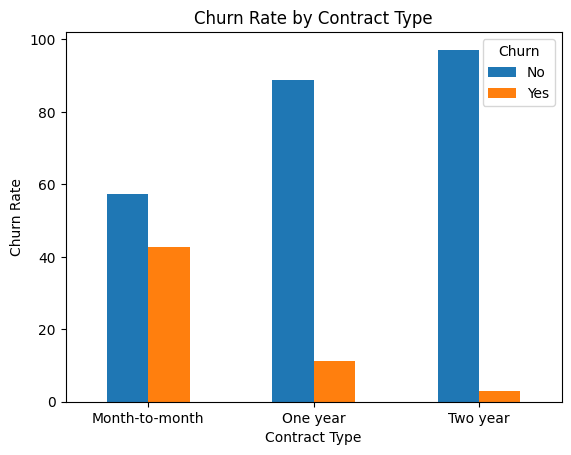

In [21]:
contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
print(contract_churn)

contract_churn.plot(kind='bar')
plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate')
plt.xticks(rotation=0)
plt.show()



The bar graph illustrates the number of customers who churned and those who did not churn, categorised according to their contract type. It also shows that the **highest number of customers who churned were on month-to-month contracts**, while customers with longer-term contracts had lower churn rates. Specifically, approximately 42.7% of customers with month to month contracts churned, compared to 11.3% of customers with on year contracts and 2.8% of customers with two-year contracts. This suggests that customers with month-to-month contracts were more likely to discontinue their services than those with longer term contracts.



### Churn or Not Churn Based on Monthly Charges

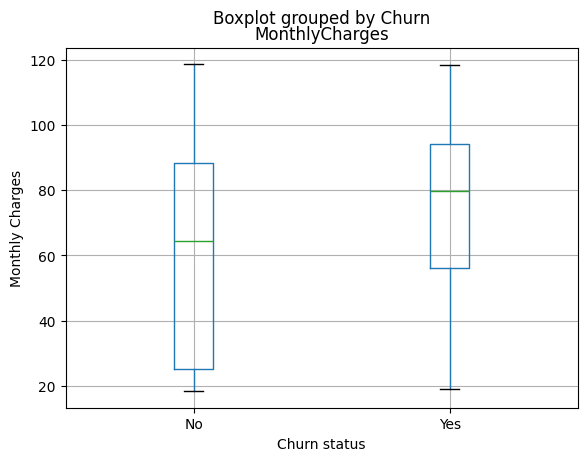

In [22]:
df.boxplot(column='MonthlyCharges',by='Churn')
plt.xlabel('Churn status')
plt.ylabel('Monthly Charges')
plt.show()




The box plot illustrates the distribution of customer tenure (the number of months customers have stayed with the company) based on their churn status. It allows us to compare the tenure of customers who churned with those who did not. If the box plot shows lower tenure values for customers who churned, this suggests that customers who have been with the company for shorter periods may be more likely to discontinue their services.


### Customer Churn by Payment Method

Percentage of payment method of differnt paying methods

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


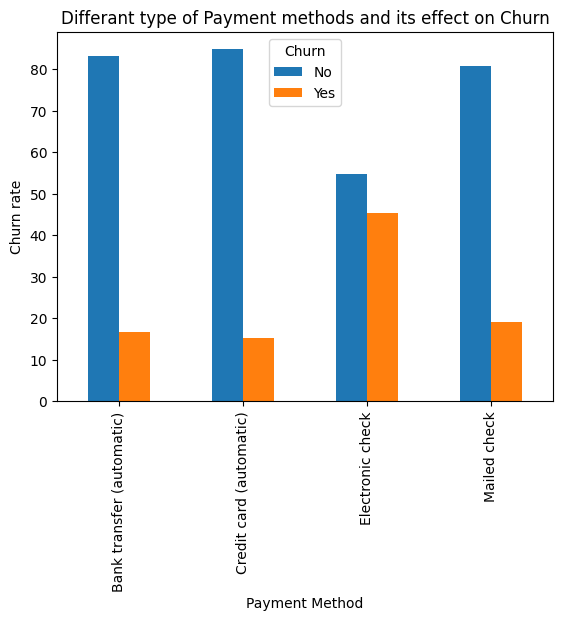

In [23]:
payment_churn=pd.crosstab(df['PaymentMethod'],df['Churn'],normalize='index')*100
print("Percentage of payment method of differnt paying methods")
print()
print(payment_churn)


payment_churn.plot(kind='bar')
plt.xlabel('Payment Method')
plt.ylabel('Churn rate')
plt.title('Differant type of Payment methods and its effect on Churn')
plt.legend(title='Churn')


The bar graph illustrates the percentage of customers who churned and those who did not churn, categorised according to their payment methods. The results show that customers who used **electronic checks had the highest churn rat**e, at approximately 45.3%. In contrast, customers who used **automatic credit card payments had the lowest churn rate**, at approximately 15.2%. Furthermore, the majority of customers using automatic bank transfers and mailed checks did not churn. These findings suggest that customer churn rates vary depending on the payment method used.


In [24]:
print("TotalCharges Data Type : ",df['Churn'].dtype)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')


print("Total number of blank cells in TotalCharges  : ",(df['TotalCharges'].isnull().sum()))

TotalCharges Data Type :  object
Total number of blank cells in TotalCharges  :  11


Above is finding how many null values exsists in entire coloumn of Total Charges.Therefore it is **11**.

# **Task 02**

### Creating the pipeLine

---



In [25]:
#removing the churn coloumn from input features which is x
X=df.drop('Churn',axis=1)
y=df['Churn']

In [26]:
X=X.drop('customerID',axis=1)# removing bcz we dont need customer id for the analysis

In [27]:
X['TotalCharges']=pd.to_numeric(X['TotalCharges'],errors='coerce') #Converting TotalCharges into numeric form

In [28]:
numerical_features=X.select_dtypes(include=['int64','float64']).columns #Returning the values where it has int and florat values from the selected coloumns

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [30]:
#first this find the missing values and then replace the missing values with the median
numerical_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),('scaler', StandardScaler())])

In [31]:
categorical_features = X.select_dtypes(include=['object']).columns #Return the values which has categorical values

In [32]:
from sklearn.preprocessing import OneHotEncoder

In [33]:
#first of all we find the missing values and its places and replace them wiht mode
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [34]:
from sklearn.compose import ColumnTransformer

In [35]:
#combining pipelines
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)])

In [36]:
from sklearn.model_selection import train_test_split

In [37]:
#here we  use 20 percent of data for tesing and 8- percent for taining
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [38]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
#use to cheack how many coloumns are trained and how many are tested

Training data: (5634, 19)
Testing data: (1409, 19)


### K-Nearest Neighbours (KNN)

---



In [39]:
from sklearn.neighbors import KNeighborsClassifier

In [40]:
#here we use our prevoiusly used pipline and combine knn ad the classifier
knn_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('knn', KNeighborsClassifier())
])


In [41]:
knn_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                ('knn', KNeighborsClassifier())])

In [42]:
y_pred=knn_model.predict(X_test) #give out the predictiontions of 5 customers

In [43]:
from sklearn.metrics import accuracy_score

In [44]:
knn_accuracy=accuracy_score(y_test,y_pred)
print("KNN Accuracy : ",knn_accuracy)

KNN Accuracy :  0.7636621717530163


In [45]:
#calculating the result accuracy whether the customer churned or not
print("KNN Accuracy as a % : ",knn_accuracy*100,"%")

KNN Accuracy as a % :  76.36621717530163 %


In [46]:
from sklearn.metrics import precision_score,recall_score,f1_score

In [47]:
#Calculating customers who has Yes(Churned)
knn_precision=precision_score(y_test,y_pred,pos_label='Yes')
print("Knn Predicition % : ",knn_precision*100,"%")

Knn Predicition % :  55.26992287917738 %


In [48]:
#Calculating the recall
knn_recall = recall_score(y_test, y_pred, pos_label='Yes')
print("KNN Recall:", knn_recall)

KNN Recall: 0.5748663101604278


In [49]:
#calculating the f1 score
knn_f1 = f1_score(y_test, y_pred, pos_label='Yes')
print("KNN F1-Score:", knn_f1)

KNN F1-Score: 0.563564875491481


In [50]:
print("KNN Evaluation Results")
print("----------------------")
print("Accuracy: ", knn_accuracy*100,"%")
print("Precision:", knn_precision*100,"%")
print("Recall:   ", knn_recall*100,"%")
print("F1-Score: ", knn_f1*100,"%")

KNN Evaluation Results
----------------------
Accuracy:  76.36621717530163 %
Precision: 55.26992287917738 %
Recall:    57.48663101604278 %
F1-Score:  56.356487549148106 %


KNN Hyperparameter Tuning

In [51]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

In [52]:
knn_params = {
    'knn__n_neighbors': [3, 5, 7, 9, 11],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

In [53]:
knn_f1_scorer = make_scorer(f1_score, pos_label='Yes')

In [54]:
knn_grid = GridSearchCV(
    estimator=knn_model,
    param_grid=knn_params,
    scoring=knn_f1_scorer,
    cv=5,
    n_jobs=-1
)

In [55]:
knn_grid.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [       nan 0.50801146 0.52069529 0.5126554         nan 0.52843972
 0.54350814 0.53386631        nan 0.53628226 0.55841112 0.54103302
        nan 0.54393079 0.56963376 0.55465142        nan 0.5548467
 0.57644973 0.56194171]
  warnings.warn(


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('e...
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                                       ('knn', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'knn__n_neighbors': [3, 5, 7, 9, 11], 'knn__p': [1, 2],
                         'knn__weights': ['uniform', 'distance']},
             scoring=make_scorer(f1_score, response_method='predict', pos_label=Yes))

In [56]:
print("Best KNN Parameters:", knn_grid.best_params_)
print("Best Cross-Validation F1-Score:", knn_grid.best_score_)

Best KNN Parameters: {'knn__n_neighbors': 11, 'knn__p': 2, 'knn__weights': 'uniform'}
Best Cross-Validation F1-Score: 0.5764497271750295


In [57]:
best_knn_model = knn_grid.best_estimator_

In [58]:
y_pred_knn_tuned = best_knn_model.predict(X_test)

In [59]:
knn_tuned_accuracy = accuracy_score(y_test, y_pred_knn_tuned)

In [60]:
knn_tuned_precision = precision_score(
    y_test, y_pred_knn_tuned, pos_label='Yes'
)

In [61]:
knn_tuned_recall = recall_score(
    y_test, y_pred_knn_tuned, pos_label='Yes'
)

In [62]:
knn_tuned_f1 = f1_score(
    y_test, y_pred_knn_tuned, pos_label='Yes'
)

In [63]:
print("\nTuned KNN Evaluation Results")
print("----------------------------")
print("Accuracy: ", knn_tuned_accuracy)
print("Precision:", knn_tuned_precision)
print("Recall:   ", knn_tuned_recall)
print("F1-Score: ", knn_tuned_f1)


Tuned KNN Evaluation Results
----------------------------
Accuracy:  0.7785663591199432
Precision: 0.5837837837837838
Recall:    0.5775401069518716
F1-Score:  0.5806451612903226


In [64]:
from sklearn.metrics import classification_report

In [65]:
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred_knn_tuned))


Detailed Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.85      0.85      1035
         Yes       0.58      0.58      0.58       374

    accuracy                           0.78      1409
   macro avg       0.72      0.71      0.72      1409
weighted avg       0.78      0.78      0.78      1409



In [66]:
import pandas as pd

knn_comparison = pd.DataFrame({
    'Original KNN': [
        knn_accuracy,
        knn_precision,
        knn_recall,
        knn_f1
    ],
    'Tuned KNN': [
        knn_tuned_accuracy,
        knn_tuned_precision,
        knn_tuned_recall,
        knn_tuned_f1
    ]
}, index=['Accuracy', 'Precision', 'Recall', 'F1-Score'])

print(knn_comparison.round(4))


           Original KNN  Tuned KNN
Accuracy         0.7637     0.7786
Precision        0.5527     0.5838
Recall           0.5749     0.5775
F1-Score         0.5636     0.5806


*Explanation*

The original KNN model achieved an **accuracy of 76.37%** and a **precision of 55.27%** for the churn class. Accuracy measures the proportion of correct predictions, while precision measures how many customers predicted to churn actually churned. Recall measures how many actual churners were correctly identified, and the F1-score balances precision and recall.
The tuned KNN model was evaluated using the same metrics to determine whether hyperparameter tuning improved its performance. The original and tuned models can be compared using their accuracy, precision, recall, and F1-scores. The best configuration was selected based on its average cross-validation F1-score, while the final evaluation was performed on the separate testing dataset.

### Logistic Regression

---


In [91]:
from sklearn.linear_model import LogisticRegression

In [92]:
from sklearn.pipeline import Pipeline

In [93]:
#Fist of all it create the pipleine we crated before which fill null values and doing preprocessing part then setting then,it iterate for 1000 times while taining the model
logreg_model=Pipeline(steps=[('preprocessor',preprocessor),('logreg',LogisticRegression(max_iter=1000))])

In [94]:
#trains the logidtic regression
logreg_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                ('logreg', LogisticRegression(max_iter=1000))])

In [95]:
y_pred_logreg=logreg_model.predict(X_test)

In [96]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [97]:
#Calcualtion of accuracy,precision,recall,f1 score
logreg_accuracy = accuracy_score(y_test, y_pred_logreg)
logreg_precision = precision_score(y_test, y_pred_logreg, pos_label='Yes')
logreg_recall = recall_score(y_test, y_pred_logreg, pos_label='Yes')
logreg_f1 = f1_score(y_test, y_pred_logreg, pos_label='Yes')

In [98]:
print("Logistic Regression Evaluation Results")
print("--------------------------------------")
print("Accuracy: ", logreg_accuracy*100,"%")
print("Precision:", logreg_precision*100,"%")
print("Recall:   ", logreg_recall*100,"%")
print("F1-Score: ", logreg_f1*100,"%")

Logistic Regression Evaluation Results
--------------------------------------
Accuracy:  80.55358410220013 %
Precision: 65.72327044025157 %
Recall:    55.88235294117647 %
F1-Score:  60.40462427745664 %


Logistic Regression Hyperparameter Tuning

In [99]:
logreg_params = {
    'logreg__C': [0.01, 0.1, 1, 10],
    'logreg__class_weight': [None, 'balanced']
}

In [100]:
logreg_f1_scorer = make_scorer(
    f1_score,
    pos_label='Yes'
)

In [101]:
logreg_grid = GridSearchCV(
    estimator=logreg_model,
    param_grid=logreg_params,
    scoring=logreg_f1_scorer,
    cv=5,
    n_jobs=-1
)


In [102]:
logreg_grid.fit(X_train, y_train)


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('e...
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                                       ('logreg',
                                        LogisticRegression(max_iter=1000))]),
             n_jobs=-1,
             param_grid={'logreg__C': [0.01, 0.1, 1, 10],
                         'logreg__class_weight': [None, 'balanced']},
             scoring=make_scorer(f1_score, response_method='predict', pos_label=Yes))

In [103]:
print("\nBest Logistic Regression Parameters:")
print(logreg_grid.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(logreg_grid.best_score_)




Best Logistic Regression Parameters:
{'logreg__C': 1, 'logreg__class_weight': 'balanced'}

Best Cross-Validation F1-Score:
0.6332167190083161


In [104]:
best_logreg_model = logreg_grid.best_estimator_


In [105]:
y_pred_logreg_tuned = best_logreg_model.predict(X_test)


In [106]:
logreg_tuned_accuracy = accuracy_score(y_test, y_pred_logreg_tuned)
logreg_tuned_precision = precision_score(y_test, y_pred_logreg_tuned, pos_label='Yes')
logreg_tuned_recall = recall_score(y_test, y_pred_logreg_tuned, pos_label='Yes')
logreg_tuned_f1 = f1_score(y_test, y_pred_logreg_tuned, pos_label='Yes')

In [107]:
print("\nTuned Logistic Regression Results")
print("---------------------------------")
print("Accuracy: ", logreg_tuned_accuracy*100,"%")
print("Precision:", logreg_tuned_precision*100,"%")
print("Recall:   ", logreg_tuned_recall*100,"%")
print("F1-Score: ", logreg_tuned_f1*100,"%")



Tuned Logistic Regression Results
---------------------------------
Accuracy:  73.81121362668559 %
Precision: 50.4302925989673 %
Recall:    78.34224598930481 %
F1-Score:  61.361256544502616 %


In [108]:
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred_logreg_tuned))


Detailed Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [109]:
logreg_comparison = pd.DataFrame({
    'Original Logistic Regression': [
        logreg_accuracy,
        logreg_precision,
        logreg_recall,
        logreg_f1
    ],
    'Tuned Logistic Regression': [
        logreg_tuned_accuracy,
        logreg_tuned_precision,
        logreg_tuned_recall,
        logreg_tuned_f1
    ]
}, index=['Accuracy', 'Precision', 'Recall', 'F1-Score'])

In [110]:
print("\nOriginal vs Tuned Logistic Regression")
print(logreg_comparison.round(4))


Original vs Tuned Logistic Regression
           Original Logistic Regression  Tuned Logistic Regression
Accuracy                         0.8055                     0.7381
Precision                        0.6572                     0.5043
Recall                           0.5588                     0.7834
F1-Score                         0.6040                     0.6136


*Explanation*

The tuned **Logistic Regression model** achieved an **accuracy of 73.81%** and a **precision of 50.43%** for the churn class (Yes). Accuracy measures the proportion of correct predictions overall, while precision measures how many customers predicted to churn actually churned. The model achieved a **recall of 78.34%**, meaning it correctly identified approximately 78.34% of the customers who actually churned. Its **F1-score was 61.36%**, representing the balance between precision and recall. The higher recall indicates that the model identified a relatively large proportion of actual churners, although its precision suggests that some customers predicted to churn did not actually churn. These results will be compared with **KNN and Random Forest** to evaluate which model performs best for customer churn prediction.
